# Week 12 Practice: Clustering and Autoencoders

CSCI1409 Deep Learning · based on the Unsupervised Learning lecture (Clustering + Autoencoders)

## Instructions

- Work in this notebook with Python and PyTorch. You can use Google Colab.
- Show your code and its output. Be ready to explain every step.
- Write short answers to the explanation questions in the **Your answer** cells.
- `sklearn` is used **only** to load the digits dataset. Write K-means yourself.

In [1]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

## Task 1: K-means clustering

We have points but **no labels**. K-means splits them into $K$ groups (clusters). Each cluster has a center called a **centroid** $\mu_k$. The algorithm repeats two steps:

1. **Assign:** give every point to its nearest centroid.
2. **Update:** move every centroid to the mean of the points it got.

It stops when the assignments do not change. The quality of a clustering is measured by the **inertia**, the sum of squared distances from each point to its centroid:

$$\text{inertia} = \sum_{i} \lVert x_i - \mu_{c(i)} \rVert^2$$

where $c(i)$ is the cluster of point $i$. Smaller inertia means tighter clusters.

### 1a) K-means by hand

Six points on a line: $X = [1, 2, 4, 7, 9, 10]$, $K = 2$, starting centroids $\mu_1 = 1$, $\mu_2 = 4$.

1. On paper, do the assign and update steps until nothing changes. For each iteration, write which points go to which cluster and the new centroids. Then compute the final inertia.
2. Write a function `kmeans(X, C)` in PyTorch. `X` has shape `[N, D]` (N points, D features) and `C` has shape `[K, D]` (starting centroids). It should return the labels, the final centroids and the inertia. Hint: `torch.cdist(X, C)` gives all distances as an `[N, K]` matrix, and `.argmin(dim=1)` picks the nearest centroid. Check it on $X$.
3. Run it again with starting centroids $\mu_1 = 9$, $\mu_2 = 10$. Do you get the same final clusters? Does it need the same number of iterations?

In [2]:
X = torch.tensor([1., 2., 4., 7., 9., 10.]).reshape(-1, 1)   # shape [6, 1]
C0 = torch.tensor([1., 4.]).reshape(-1, 1)                   # shape [2, 1]


def kmeans(X, C, max_iters=100, verbose=False):
    C = C.clone().float()
    labels = None
    for it in range(1, max_iters + 1):
        # Step 1: assign every point to its nearest centroid
        new_labels = torch.cdist(X, C).argmin(dim=1)
        if labels is not None and torch.equal(new_labels, labels):
            break                       # assignments did not change -> converged
        labels = new_labels
        # Step 2: move every centroid to the mean of its points
        for k in range(C.shape[0]):
            pts = X[labels == k]
            if len(pts) > 0:            # keep old centroid if cluster is empty
                C[k] = pts.mean(dim=0)
        if verbose:
            print(f"iter {it}: labels={labels.tolist()}, centroids={C.squeeze().tolist()}")
    inertia = ((X - C[labels]) ** 2).sum().item()
    return labels, C, inertia


print("Start (1, 4):")
labels, C, inertia = kmeans(X, C0, verbose=True)
print("labels:", labels.tolist(), "centroids:", C.squeeze().tolist(), "inertia:", round(inertia, 3))

print("\nStart (9, 10):")
labels2, C2, inertia2 = kmeans(X, torch.tensor([[9.], [10.]]), verbose=True)
print("labels:", labels2.tolist(), "centroids:", C2.squeeze().tolist(), "inertia:", round(inertia2, 3))

Start (1, 4):
iter 1: labels=[0, 0, 1, 1, 1, 1], centroids=[1.5, 7.5]
iter 2: labels=[0, 0, 0, 1, 1, 1], centroids=[2.3333332538604736, 8.666666984558105]
labels: [0, 0, 0, 1, 1, 1] centroids: [2.3333332538604736, 8.666666984558105] inertia: 9.333

Start (9, 10):
iter 1: labels=[0, 0, 0, 0, 0, 1], centroids=[4.599999904632568, 10.0]
iter 2: labels=[0, 0, 0, 0, 1, 1], centroids=[3.5, 9.5]
iter 3: labels=[0, 0, 0, 1, 1, 1], centroids=[2.3333332538604736, 8.666666984558105]
labels: [0, 0, 0, 1, 1, 1] centroids: [2.3333332538604736, 8.666666984558105] inertia: 9.333


**Your answer:**

**1) By hand** ($\mu_1=1, \mu_2=4$):

| Iter | Cluster 1 | Cluster 2 | New $\mu_1$ | New $\mu_2$ |
|---|---|---|---|---|
| 1 | {1, 2} | {4, 7, 9, 10} | 1.5 | 7.5 |
| 2 | {1, 2, 4} | {7, 9, 10} | 2.333 | 8.667 |
| 3 | {1, 2, 4} | {7, 9, 10} | — no change, stop | |

Final inertia: $(1-2.333)^2 + (2-2.333)^2 + (4-2.333)^2 + (7-8.667)^2 + (9-8.667)^2 + (10-8.667)^2 = 4.667 + 4.667 = \mathbf{9.333}$.

**2)** The PyTorch function gives the same labels, centroids (2.333, 8.667) and inertia 9.333.

**3)** Start $\mu_1=9, \mu_2=10$: iter 1 → {1,2,4,7,9} / {10}, centroids 4.6, 10; iter 2 → {1,2,4,7} / {9,10}, centroids 3.5, 9.5; iter 3 → {1,2,4} / {7,9,10}, centroids 2.333, 8.667; iter 4 → no change.
We get the **same final clusters** (and inertia 9.333), but it needs **more iterations** (3 updates instead of 2), because the starting centroids are far from the final ones. In general K-means depends on the initialization and can even end in a different (worse) local minimum.

### 1b) How many clusters? The elbow method

K-means needs $K$ from us. One common way to choose it is the **elbow method**: run K-means for $K = 1, 2, \dots$ and plot the inertia. The inertia always goes down, but at some $K$ it stops going down fast. That bend (the "elbow") is a good choice.

```python
torch.manual_seed(0)
centers = torch.tensor([[0., 0.], [5., 5.], [0., 6.]])
data = torch.cat([c + torch.randn(50, 2) for c in centers])   # 150 points in 2D
```

1. Plot `data` with `plt.scatter`. How many groups do you see?
2. For each $K$ from 1 to 6, start from $K$ random data points as centroids (`data[torch.randperm(len(data))[:K]]`) and run your `kmeans`. Print the inertia for each $K$ and plot inertia against $K$. Where is the elbow?
3. Plot the clusters for the $K$ you chose (color = label). Why does the inertia keep going down after the elbow? Why do we not just pick the $K$ with the smallest inertia?

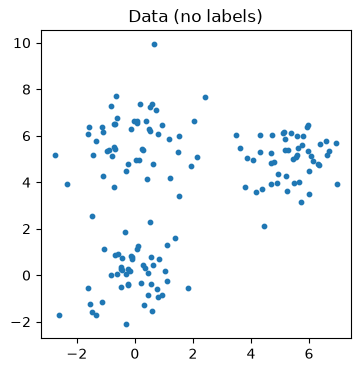

K=1: inertia=2242.78
K=2: inertia=1126.00
K=3: inertia=309.95
K=4: inertia=277.75
K=5: inertia=224.76
K=6: inertia=209.90


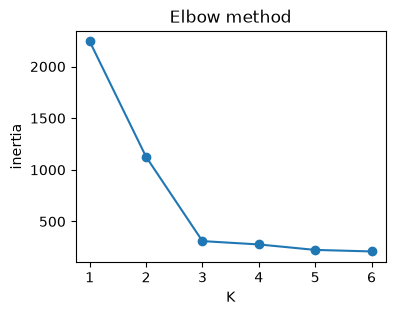

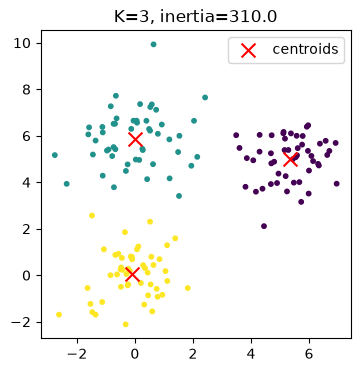

In [3]:
torch.manual_seed(0)
centers = torch.tensor([[0., 0.], [5., 5.], [0., 6.]])
data = torch.cat([c + torch.randn(50, 2) for c in centers])   # 150 points in 2D

# 1) raw data
plt.figure(figsize=(4, 4))
plt.scatter(data[:, 0], data[:, 1], s=10)
plt.title("Data (no labels)")
plt.show()

# 2) elbow method
inertias = []
for K in range(1, 7):
    C_init = data[torch.randperm(len(data))[:K]]
    _, _, inertia = kmeans(data, C_init)
    inertias.append(inertia)
    print(f"K={K}: inertia={inertia:.2f}")

plt.figure(figsize=(4, 3))
plt.plot(range(1, 7), inertias, "o-")
plt.xlabel("K"); plt.ylabel("inertia"); plt.title("Elbow method")
plt.show()

# 3) clusters for K = 3
torch.manual_seed(1)
labels, C, inertia = kmeans(data, data[torch.randperm(len(data))[:3]])
plt.figure(figsize=(4, 4))
plt.scatter(data[:, 0], data[:, 1], c=labels, s=10, cmap="viridis")
plt.scatter(C[:, 0], C[:, 1], c="red", marker="x", s=100, label="centroids")
plt.legend(); plt.title(f"K=3, inertia={inertia:.1f}")
plt.show()

**Your answer:**

1. The scatter plot shows **3 groups** (around (0,0), (5,5) and (0,6)).
2. The inertia drops a lot from K=1 to K=2 and from K=2 to K=3, and after that it decreases only slowly. The **elbow is at K = 3**.
3. With K = 3 every blob gets its own cluster. The inertia keeps going down after the elbow because more centroids always means each point is closer to some centroid (in the extreme, K = N gives inertia 0, every point is its own cluster). So the smallest inertia is not a useful criterion — it would just pick the largest K and split real groups into meaningless pieces. We look for the point where adding a cluster stops giving a big improvement.

## Task 2: Autoencoders

An **autoencoder** is a neural network that learns to copy its input to its output, but through a narrow middle layer:

- the **encoder** squeezes the input $x$ into a small vector $z$, the **latent code** (or bottleneck),
- the **decoder** tries to rebuild $x$ from $z$. We call the result $\hat{x}$.

The loss compares the output with the input itself, for example $\text{MSE}(\hat{x}, x)$. **No labels are needed**, so this is unsupervised learning. Because $z$ is small, the network cannot memorize everything and has to keep only the most important information.

### 2a) Build an autoencoder: shapes and parameters

A `nn.Linear(a, b)` layer has $a \cdot b + b$ parameters (weights plus biases). Here is an autoencoder for 28×28 images (784 pixels) with bottleneck size $L$:

```python
encoder = nn.Sequential(nn.Linear(784, 128), nn.ReLU(), nn.Linear(128, L))
decoder = nn.Sequential(nn.Linear(L, 128), nn.ReLU(), nn.Linear(128, 784), nn.Sigmoid())
```

| Case | $L$ |
|---|---|
| A | 32 |
| B | 2 |
| C | 784 |

1. For each case, predict the shape of `z = encoder(x)` and of `x_hat = decoder(z)` for `x = torch.rand(16, 784)`, and the total number of parameters. How many times smaller is $z$ than $x$?
2. Check with PyTorch.
3. Why is there a `Sigmoid` at the end of the decoder? Why is case C a bad autoencoder, even though it can rebuild the input perfectly?

In [4]:
x = torch.rand(16, 784)   # 16 images with pixel values between 0 and 1

for name, L in [("A", 32), ("B", 2), ("C", 784)]:
    encoder = nn.Sequential(nn.Linear(784, 128), nn.ReLU(), nn.Linear(128, L))
    decoder = nn.Sequential(nn.Linear(L, 128), nn.ReLU(), nn.Linear(128, 784), nn.Sigmoid())
    z = encoder(x)
    x_hat = decoder(z)
    n_params = sum(p.numel() for p in encoder.parameters()) + sum(p.numel() for p in decoder.parameters())
    print(f"Case {name} (L={L}): z {tuple(z.shape)}, x_hat {tuple(x_hat.shape)}, "
          f"params={n_params}, z is {784 / L:.1f}x smaller than x")

Case A (L=32): z (16, 32), x_hat (16, 784), params=209968, z is 24.5x smaller than x
Case B (L=2): z (16, 2), x_hat (16, 784), params=202258, z is 392.0x smaller than x
Case C (L=784): z (16, 784), x_hat (16, 784), params=403232, z is 1.0x smaller than x


**Your answer:**

**1) Predictions** (encoder: $784\cdot128+128 = 100480$ plus $128L+L$; decoder: $128L+128$ plus $128\cdot784+784 = 101136$):

| Case | $L$ | `z` shape | `x_hat` shape | Parameters | $x$ / $z$ |
|---|---|---|---|---|---|
| A | 32 | [16, 32] | [16, 784] | 209 968 | 24.5× |
| B | 2 | [16, 2] | [16, 784] | 202 258 | 392× |
| C | 784 | [16, 784] | [16, 784] | 403 232 | 1× |

**2)** PyTorch prints the same shapes and parameter counts.

**3)** The input pixels are between 0 and 1, so the `Sigmoid` squeezes the output into (0, 1) as well — the reconstruction lives in the same range as the input.
Case C has a bottleneck as large as the input, so there is no compression: the network can just learn (close to) the identity function and copy $x$. Then $z$ is not a compressed or meaningful representation — the network is not forced to learn the important structure of the data, which is the whole point of an autoencoder.

### 2b) Train an autoencoder on handwritten digits

We use the small digits dataset from `sklearn`: 1797 images of 8×8 pixels (64 numbers per image), digits 0 to 9.

```python
from sklearn.datasets import load_digits
digits = load_digits()
X = torch.tensor(digits.data, dtype=torch.float32) / 16   # pixels from 0 to 1, shape [1797, 64]
y = torch.tensor(digits.target)                           # only for plots, NOT for training
```

Use this autoencoder with bottleneck size $L$:

```python
encoder = nn.Sequential(nn.Linear(64, 32), nn.ReLU(), nn.Linear(32, L))
decoder = nn.Sequential(nn.Linear(L, 32), nn.ReLU(), nn.Linear(32, 64), nn.Sigmoid())
```

1. Write a training loop: Adam with `lr=0.01`, MSE loss between `decoder(encoder(X))` and `X`, 500 steps on the whole dataset at once. Train with $L = 2$ and with $L = 16$ (use `torch.manual_seed(0)` before creating each model). Print the final loss for both.
2. Show 8 original images and their reconstructions for both models (use `.reshape(8, 8)` and `plt.imshow`).
3. Which model rebuilds the digits better, and why? Where in the training did we use the labels `y`?

L=2: final loss = 0.0362


L=16: final loss = 0.0095


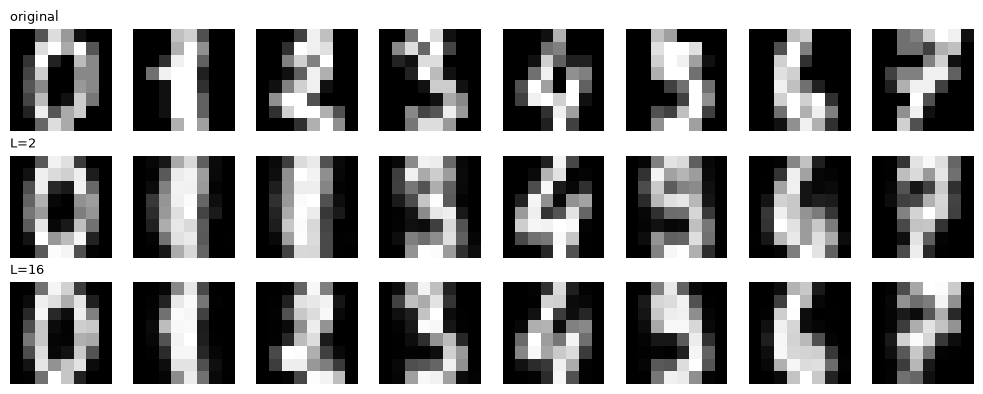

In [5]:
from sklearn.datasets import load_digits
digits = load_digits()
X = torch.tensor(digits.data, dtype=torch.float32) / 16   # pixels from 0 to 1, shape [1797, 64]
y = torch.tensor(digits.target)                           # only for plots, NOT for training


def train_autoencoder(L, steps=500):
    torch.manual_seed(0)
    encoder = nn.Sequential(nn.Linear(64, 32), nn.ReLU(), nn.Linear(32, L))
    decoder = nn.Sequential(nn.Linear(L, 32), nn.ReLU(), nn.Linear(32, 64), nn.Sigmoid())
    opt = torch.optim.Adam(list(encoder.parameters()) + list(decoder.parameters()), lr=0.01)
    loss_fn = nn.MSELoss()
    for step in range(steps):
        x_hat = decoder(encoder(X))
        loss = loss_fn(x_hat, X)          # compare with the input itself, no labels
        opt.zero_grad()
        loss.backward()
        opt.step()
    print(f"L={L}: final loss = {loss.item():.4f}")
    return encoder, decoder


models = {L: train_autoencoder(L) for L in [2, 16]}

# show 8 originals and their reconstructions
fig, axes = plt.subplots(3, 8, figsize=(10, 4))
with torch.no_grad():
    rec = {L: dec(enc(X[:8])) for L, (enc, dec) in models.items()}
rows = [("original", X[:8]), ("L=2", rec[2]), ("L=16", rec[16])]
for r, (title, imgs) in enumerate(rows):
    for i in range(8):
        axes[r, i].imshow(imgs[i].reshape(8, 8), cmap="gray")
        axes[r, i].axis("off")
    axes[r, 0].set_title(title, fontsize=9, loc="left")
plt.tight_layout()
plt.show()

**Your answer:**

The model with **L = 16 rebuilds the digits much better** (lower final loss, reconstructions look almost like the originals), while L = 2 gives blurry, "average-looking" digits and sometimes the wrong digit. With only 2 numbers the bottleneck can keep only very coarse information about the image (roughly *which kind* of digit), while 16 numbers can also store details like stroke shape and thickness. (Both are still compressions of the 64 pixels.)

We **never used the labels `y`** in training — the loss only compares `decoder(encoder(X))` with `X`. `y` is only used for plotting/coloring. This is unsupervised learning.

## Stretch (optional)

**A) Fuzzy K-means.** In normal ("hard") K-means each point belongs to one cluster. In **fuzzy K-means** each point gets a membership between 0 and 1 for every cluster, and the memberships add up to 1. With fuzziness $m = 2$, the membership of point $x$ in cluster 1 (of two clusters) is

$$u_1 = \frac{1}{1 + \left(\dfrac{d_1}{d_2}\right)^2}$$

where $d_1, d_2$ are the distances from $x$ to the two centroids. Use the final centroids of 1a (2.333 and 8.667). Compute $u_1$ and $u_2$ for the point 4 and for the point 7. Which point is "more sure" about its cluster?

**B) Clustering in the latent space.** Take the codes `z = encoder(X)` of the $L = 2$ model from 2b and plot them with `plt.scatter`, colored by `y`. Do images of the same digit land near each other? Then run your `kmeans` on the codes with $K = 10$.

point 4: d1=1.667, d2=4.667, u1=0.887, u2=0.113
point 7: d1=4.667, d2=1.667, u1=0.113, u2=0.887


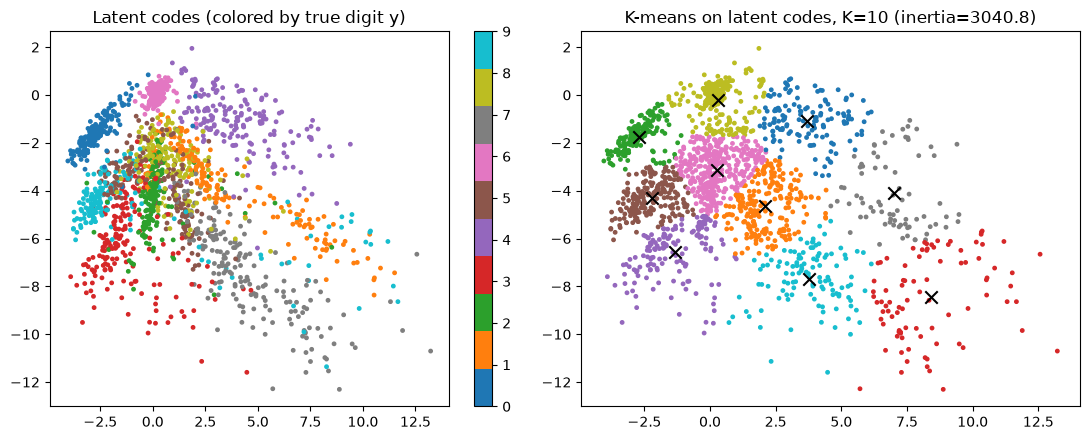

cluster 0:  137 points, most common digit 4 (91%)
cluster 1:  221 points, most common digit 5 (30%)
cluster 2:  173 points, most common digit 0 (93%)
cluster 3:   88 points, most common digit 7 (56%)
cluster 4:  155 points, most common digit 3 (68%)
cluster 5:  212 points, most common digit 9 (60%)
cluster 6:  356 points, most common digit 2 (31%)
cluster 7:   76 points, most common digit 1 (47%)
cluster 8:  263 points, most common digit 6 (68%)
cluster 9:  116 points, most common digit 7 (71%)


In [6]:
# A) Fuzzy K-means memberships (m = 2) with centroids from 1a
mu1, mu2 = 7 / 3, 26 / 3
for p in [4., 7.]:
    d1, d2 = abs(p - mu1), abs(p - mu2)
    u1 = 1 / (1 + (d1 / d2) ** 2)
    print(f"point {p:g}: d1={d1:.3f}, d2={d2:.3f}, u1={u1:.3f}, u2={1 - u1:.3f}")

# B) Clustering in the latent space of the L = 2 model
enc2, dec2 = models[2]
with torch.no_grad():
    z = enc2(X)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
sc = axes[0].scatter(z[:, 0], z[:, 1], c=y, cmap="tab10", s=6)
axes[0].set_title("Latent codes (colored by true digit y)")
fig.colorbar(sc, ax=axes[0], ticks=range(10))

torch.manual_seed(0)
z_labels, z_C, z_inertia = kmeans(z, z[torch.randperm(len(z))[:10]])
axes[1].scatter(z[:, 0], z[:, 1], c=z_labels, cmap="tab10", s=6)
axes[1].scatter(z_C[:, 0], z_C[:, 1], c="black", marker="x", s=80)
axes[1].set_title(f"K-means on latent codes, K=10 (inertia={z_inertia:.1f})")
plt.tight_layout()
plt.show()

# how pure is each k-means cluster w.r.t. the true digits?
for k in range(10):
    digits_in_k = y[z_labels == k]
    if len(digits_in_k):
        top = torch.mode(digits_in_k).values.item()
        print(f"cluster {k}: {len(digits_in_k):4d} points, most common digit {top} "
              f"({(digits_in_k == top).float().mean():.0%})")

**Your answer (stretch):**

**A)** Point 4: $d_1 = 1.667$, $d_2 = 4.667$, $u_1 = 1/(1 + (5/14)^2) = 196/221 \approx 0.887$, $u_2 \approx 0.113$.
Point 7: $d_1 = 4.667$, $d_2 = 1.667$, $u_1 \approx 0.113$, $u_2 \approx 0.887$.
The situation is symmetric: each point is at distance 1.667 from its own centroid and 4.667 from the other, so both are **equally sure** (0.887) — point 4 about cluster 1 and point 7 about cluster 2. A point like 5.5 (halfway) would get 0.5 / 0.5.

**B)** In the 2D latent space images of the same digit mostly land near each other (e.g. 0 and 4 form very clean groups, ~90% pure clusters), even though the autoencoder never saw the labels. Some digits overlap (e.g. 1, 2, 5, 8 get mixed with others), because 2 numbers are not enough to separate all of them. K-means with K = 10 on the codes finds clusters that often match a single digit, but the overlapping digits get mixed or split.
